# XGBoost

## Clasificador

In [1]:
import pandas as pd

df = pd.read_csv(
    "http://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data",
    header=None,
    names=['age', 'workclass', 'fnlwgt', 'education', 'education-num',
           'marital-status', 'occupation', 'relationship','race', 'sex',
           'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income'],
    na_values=' ?'
    )

df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       30725 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education-num   32561 non-null  int64 
 5   marital-status  32561 non-null  object
 6   occupation      30718 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital-gain    32561 non-null  int64 
 11  capital-loss    32561 non-null  int64 
 12  hours-per-week  32561 non-null  int64 
 13  native-country  31978 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


Para que funcione el procesamiento nativo de variables categóricas, es necesario convertir estas variables de tipo **object** (o **str**) a tipo **category**:

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

X = df.drop('income', axis=1)
y = df['income']

orden = [
    ' Preschool', ' 1st-4th', ' 5th-6th', ' 7th-8th', ' 9th', ' 10th',' 11th', ' 12th',
    ' HS-grad',' Some-college', ' Assoc-acdm', ' Assoc-voc', ' Bachelors', ' Masters',
    ' Prof-school', ' Doctorate'
         ]
X['education'] = pd.Categorical(X['education'], categories=orden, ordered=True)

categorical_features = X.select_dtypes(include='object').columns.to_list()
X[categorical_features] = X[categorical_features].astype('category')

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=1,
    stratify=y
    )

le = LabelEncoder()
y_train = le.fit_transform(y_train)
y_test = le.fit_transform(y_test)

Se va a entrenar un modelo sin sintonizar hiperparámetros:

In [4]:
from xgboost import XGBClassifier

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb_model = XGBClassifier(
    grow_policy='lossguide',
    tree_method='hist',
    enable_categorical=True,
    scale_pos_weight=scale_pos_weight,
    random_state=1,
    n_jobs=-1
)

xgb_model.fit(
    X_train,
    y_train,
    )

print(f'Train score: {xgb_model.score(X_train, y_train):.3f}')
print(f'Test score: {xgb_model.score(X_test, y_test):.3f}')

Train score: 0.889
Test score: 0.839


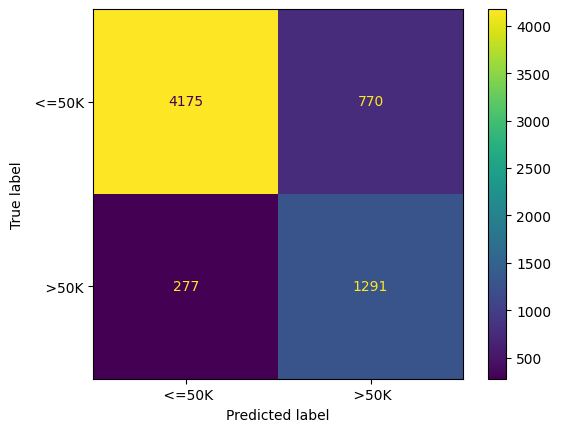

In [5]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(
    xgb_model, 
    X_test, 
    y_test, 
    display_labels=le.classes_
    );

In [6]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test, 
    xgb_model.predict(X_test), 
    target_names=le.classes_
    ))

              precision    recall  f1-score   support

       <=50K       0.94      0.84      0.89      4945
        >50K       0.63      0.82      0.71      1568

    accuracy                           0.84      6513
   macro avg       0.78      0.83      0.80      6513
weighted avg       0.86      0.84      0.85      6513



Ahora se va a sintonizar:

In [7]:
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import RandomizedSearchCV

dist_xgb = {
    'n_estimators': randint(50, 400),
    'max_depth': randint(3, 8),
    'learning_rate': loguniform(0.01, 0.3),
    'subsample': uniform(0.6, 0.4),
    'colsample_bytree': uniform(0.6, 0.4),
    'min_child_weight': randint(1, 10),
    'gamma': uniform(0, 5),
    'reg_alpha': loguniform(1e-3, 10),
    'reg_lambda': loguniform(1e-3, 10)
}

rs_xgb = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=dist_xgb,
    n_iter=20,
    scoring='f1_weighted',
    cv=3,
    random_state=1,
    n_jobs=-1
)

rs_xgb.fit(X_train, y_train)

print(f'Mejor F1 ponderado: {rs_xgb.best_score_:.3f}')
print(f'Parámetros óptimos: {rs_xgb.best_params_}')
print(f'Train score: {rs_xgb.score(X_train, y_train):.3f}')
print(f'Test score: {rs_xgb.score(X_test, y_test):.3f}')

Mejor F1 ponderado: 0.847
Parámetros óptimos: {'colsample_bytree': np.float64(0.7159040010958143), 'gamma': np.float64(3.5869580062890494), 'learning_rate': np.float64(0.08042640487211762), 'max_depth': 6, 'min_child_weight': 1, 'n_estimators': 360, 'reg_alpha': np.float64(0.973837672309104), 'reg_lambda': np.float64(0.16786530193927102), 'subsample': np.float64(0.6545820902642739)}
Train score: 0.881
Test score: 0.847


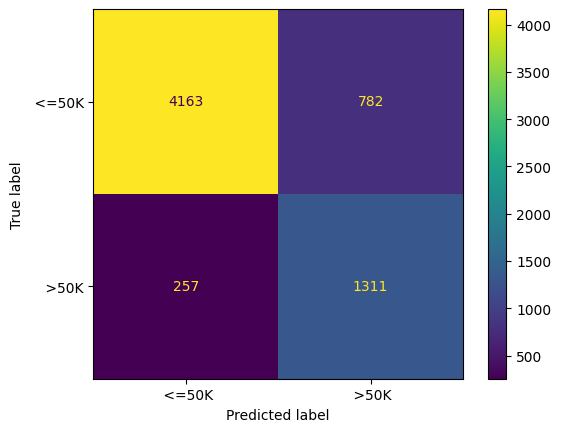

In [8]:
ConfusionMatrixDisplay.from_estimator(
    rs_xgb.best_estimator_,
    X_test,
    y_test,
    display_labels=le.classes_
    );

In [9]:
print(classification_report(
    y_test,
    rs_xgb.best_estimator_.predict(X_test),
    target_names=le.classes_
    ))

              precision    recall  f1-score   support

       <=50K       0.94      0.84      0.89      4945
        >50K       0.63      0.84      0.72      1568

    accuracy                           0.84      6513
   macro avg       0.78      0.84      0.80      6513
weighted avg       0.87      0.84      0.85      6513



Este modelo también da información acerca de la importancia relativa de cada característica:

In [10]:
xgb_features = pd.DataFrame({
    'Feature': rs_xgb.best_estimator_.feature_names_in_,
    'Importance': rs_xgb.best_estimator_.feature_importances_
})

xgb_features.sort_values('Importance', ascending=False)

,Feature,Importance
7,relationship,0.208183
10,capital-gain,0.159464
5,marital-status,0.146211
9,sex,0.088538
4,education-num,0.060613
0,age,0.058161
11,capital-loss,0.056698
6,occupation,0.055598
3,education,0.049777
12,hours-per-week,0.032447


## Regresor

In [11]:
from pathlib import Path

data_dir = Path().resolve().parent / "data" / "raw"
data_name = "home_data.csv"
filepath = data_dir / data_name

df = pd.read_csv(filepath)
df.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


In [12]:
from sklearn.model_selection import train_test_split

df = df.drop(columns=['id', 'date'], axis=1)

X = df.drop(columns=['price'])
y = df['price']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=1
    )

print(X_train.shape)
print(X_test.shape)

(17290, 18)
(4323, 18)


In [13]:
from sklearn.metrics import root_mean_squared_error
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    grow_policy='lossguide',
    tree_method='hist',
    random_state=1,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

train_score = root_mean_squared_error(y_train, xgb_model.predict(X_train))
test_score = root_mean_squared_error(y_test, xgb_model.predict(X_test))
print(f'Train score: {train_score:.3f}')
print(f'Test score: {test_score:.3f}')

Train score: 55703.562
Test score: 151088.000


In [14]:
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import RandomizedSearchCV

dist_xgb = {
    'n_estimators': randint(50, 400),
    'max_depth': randint(3, 8),
    'learning_rate': loguniform(0.01, 0.3),
    'subsample': uniform(0.6, 0.4),
    'colsample_bytree': uniform(0.6, 0.4),
    'min_child_weight': randint(1, 10),
    'gamma': uniform(0, 5),
    'reg_alpha': loguniform(1e-3, 10),
    'reg_lambda': loguniform(1e-3, 10)
}

rs_xgb = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=dist_xgb,
    n_iter=20,
    scoring='neg_root_mean_squared_error',
    cv=3,
    random_state=1,
    n_jobs=-1
)

rs_xgb.fit(X_train, y_train)

print(f'Mejor RMSE: {-rs_xgb.best_score_:.3f}')
print(f'Parámetros óptimos: {rs_xgb.best_params_}')
print(f'Train RMSE: {-rs_xgb.score(X_train, y_train):.3f}')
print(f'Test RMSE: {-rs_xgb.score(X_test, y_test):.3f}')

Mejor RMSE: 116063.312
Parámetros óptimos: {'colsample_bytree': np.float64(0.620007234355297), 'gamma': np.float64(3.7047777786794214), 'learning_rate': np.float64(0.027617663513487115), 'max_depth': 7, 'min_child_weight': 5, 'n_estimators': 338, 'reg_alpha': np.float64(2.0697771981533504), 'reg_lambda': np.float64(0.004238045144438539), 'subsample': np.float64(0.6074304808709637)}
Train RMSE: 72925.625
Test RMSE: 144890.594


In [15]:
xgb_features = pd.DataFrame({
    'Feature': rs_xgb.best_estimator_.feature_names_in_,
    'Importance': rs_xgb.best_estimator_.feature_importances_
})

xgb_features.sort_values('Importance', ascending=False)

,Feature,Importance
8,grade,0.318974
2,sqft_living,0.142587
5,waterfront,0.115853
14,lat,0.067869
6,view,0.053001
1,bathrooms,0.046059
9,sqft_above,0.045590
16,sqft_living15,0.036555
15,long,0.035596
11,yr_built,0.028248
